In [1]:
print("Starting my Credit Risk Research Project")

Starting my Credit Risk Research Project


In [2]:
%pip install pandas ucimlrepo


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from ucimlrepo import fetch_ucirepo
dataset = fetch_ucirepo(id=350)
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
X=dataset.data.features
y=dataset.data.targets
print(X.shape)
print(y.shape)

(30000, 23)
(30000, 1)


In [5]:
X.head(10)

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679
5,50000,1,1,2,37,0,0,0,0,0,...,57608,19394,19619,20024,2500,1815,657,1000,1000,800
6,500000,1,1,2,29,0,0,0,0,0,...,445007,542653,483003,473944,55000,40000,38000,20239,13750,13770
7,100000,2,2,2,23,0,-1,-1,0,0,...,601,221,-159,567,380,601,0,581,1687,1542
8,140000,2,3,1,28,0,0,2,0,0,...,12108,12211,11793,3719,3329,0,432,1000,1000,1000
9,20000,1,3,2,35,-2,-2,-2,-2,-1,...,0,0,13007,13912,0,0,0,13007,1122,0


In [6]:
dataset.variables.head(24)

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,NaN,NaN,None,no
1,X1,Feature,Integer,NaN,LIMIT_BAL,None,no
2,X2,Feature,Integer,Sex,SEX,None,no
3,X3,Feature,Integer,Education Level,EDUCATION,None,no
4,X4,Feature,Integer,Marital Status,MARRIAGE,None,no
5,X5,Feature,Integer,Age,AGE,None,no
6,X6,Feature,Integer,NaN,PAY_0,None,no
7,X7,Feature,Integer,NaN,PAY_2,None,no
8,X8,Feature,Integer,NaN,PAY_3,None,no
9,X9,Feature,Integer,NaN,PAY_4,None,no


In [7]:
y.head()

,Y
0,1
1,1
2,0
3,0
4,0


In [8]:
y["Y"].value_counts()

Y
0    23364
1     6636
Name: count, dtype: int64

In [9]:
default_rate = y["Y"].mean() * 100
print(default_rate)

22.12


In [10]:
average_limit = X["X1"].mean()
print(average_limit)

167484.32266666667


In [11]:
X["X1"].describe()

count      30000.000000
mean      167484.322667
std       129747.661567
min        10000.000000
25%        50000.000000
50%       140000.000000
75%       240000.000000
max      1000000.000000
Name: X1, dtype: float64

In [12]:
credit_data = X[["X1"]].copy()
credit_data["Y"] = y["Y"]
credit_data.head(15)

,X1,Y
0,20000,1
1,120000,1
2,90000,0
3,50000,0
4,50000,0
5,50000,0
6,500000,0
7,100000,0
8,140000,0
9,20000,0


In [13]:
credit_data.groupby("Y")["X1"].mean()

Y
0    178099.726074
1    130109.656420
Name: X1, dtype: float64

In [14]:
import pandas as pd
credit_data["limit_group"] = pd.cut(credit_data["X1"], bins=[0, 50000, 100000, 200000, 500000, 1000000])
credit_data.head()


,X1,Y,limit_group
0,20000,1,"(0, 50000]"
1,120000,1,"(100000, 200000]"
2,90000,0,"(50000, 100000]"
3,50000,0,"(0, 50000]"
4,50000,0,"(0, 50000]"


In [15]:
default_by_limit = (credit_data.groupby("limit_group", observed=True)["Y"].mean()*100)
print(default_by_limit)

limit_group
(0, 50000]           31.787389
(50000, 100000]      25.798424
(100000, 200000]     19.479695
(200000, 500000]     14.804588
(500000, 1000000]    11.165049
Name: Y, dtype: float64


In [16]:
%pip install matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


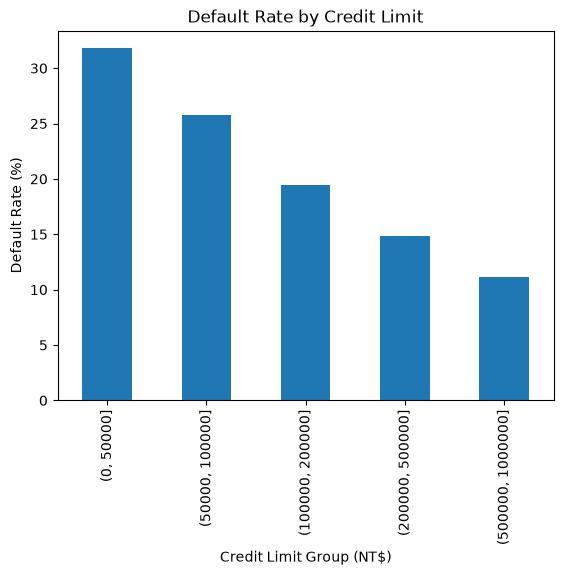

In [17]:
import matplotlib.pyplot as plt
default_by_limit.plot(kind="bar")
plt.title("Default Rate by Credit Limit")
plt.xlabel("Credit Limit Group (NT$)")
plt.ylabel("Default Rate (%)")
plt.show()

In [18]:
group_counts = credit_data.groupby("limit_group", observed=True)["Y"].count()
print(group_counts)

limit_group
(0, 50000]           7676
(50000, 100000]      4822
(100000, 200000]     7880
(200000, 500000]     9416
(500000, 1000000]     206
Name: Y, dtype: int64


In [19]:
group_summary = credit_data.groupby("limit_group", observed=True)["Y"].agg(["count", "sum", "mean"])
group_summary

,count,sum,mean
limit_group,,,
"(0, 50000]",7676,2440,0.317874
"(50000, 100000]",4822,1244,0.257984
"(100000, 200000]",7880,1535,0.194797
"(200000, 500000]",9416,1394,0.148046
"(500000, 1000000]",206,23,0.111650


In [20]:
summary_table = group_summary.rename(columns={"count": "customers", "sum": "defaults", "mean": "default_rate_percent"}).copy()
summary_table["default_rate_percent"] = (summary_table["default_rate_percent"] * 100).round(2)
print(summary_table)

                   customers  defaults  default_rate_percent
limit_group                                                 
(0, 50000]              7676      2440                 31.79
(50000, 100000]         4822      1244                 25.80
(100000, 200000]        7880      1535                 19.48
(200000, 500000]        9416      1394                 14.80
(500000, 1000000]        206        23                 11.17
